# 04 · Superresolución con otras resoluciones (nivel avanzado)

**Objetivo:** ampliar el estudio del nivel básico (`03_superres_basico.ipynb`) con **otras resoluciones de entrada y de salida**.

- Usamos el **autoencoder convolucional**, que fue el mejor en `01_ruido_basico.ipynb` y en `03_superres_basico.ipynb`.
- **Parte A · otras entradas:** n×n → 28×28 con n = **4, 10 y 21**. Volvemos a entrenar también 7 y 14 con el mismo código para tener la curva completa del error según el tamaño de entrada.
- **Parte B · otras salidas:** **7×7 → 14×14** y **14×14 → 56×56**. Solo cambia el final del decoder (una capa de ampliación menos o una más).
- Reducción y ampliación del objetivo: `v2.functional.resize(imagen, [m, m], antialias=True)`, lote a lote.
- Mismos hiperparámetros que el resto (MSE, Adam lr=0.001, batch 64, 10 epochs) y misma semilla.
- Referencia sin aprendizaje: ampliar la entrada con interpolación bilineal hasta el tamaño de salida.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
from torchvision.transforms import v2
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
# GPU de NVIDIA (cuda), GPU de los Mac con chip Apple (mps) o CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Dispositivo activo: {device}")

Dispositivo activo: cuda


In [2]:
# Transformación limpia: a Tensor y escalado [0.0, 1.0]
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

## Cambiar la resolución

In [3]:
def redimensionar(images, m):
    # Cambiamos el lote a m×m. Al reducir, antialias suaviza antes de submuestrear (como al encoger una foto)
    return v2.functional.resize(images, [m, m], antialias=True)


def objetivo(images, n_salida):
    # Imagen que debe generar el autoencoder: la original a 28×28, o la original llevada al tamaño de salida
    return images if n_salida == 28 else redimensionar(images, n_salida)

## Autoencoder de superresolución con entrada y salida configurables

- **Encoder** (igual que en `03`): dos convoluciones con `stride=1` (mantienen el tamaño n×n porque la entrada ya es pequeña), `Flatten` y `Linear(32·n·n → 64)`.
- **Decoder:** el de clase (`Linear(64 → 32·7·7)`, `Unflatten` y `ConvTranspose2d` con `stride=2`, que duplica el tamaño). Lo adaptamos al tamaño de salida:
  - **14×14:** 7 → 14 y una última `ConvTranspose2d` con `stride=1` que solo deja 1 canal.
  - **28×28:** el decoder de clase sin cambios (7 → 14 → 28).
  - **56×56:** una ampliación más (7 → 14 → 28 → 56).

In [4]:
class AutoencoderSuperresCNN(nn.Module):
    def __init__(self, n_entrada, n_salida=28):
        super().__init__()
        assert n_salida in (14, 28, 56), "El decoder solo genera 14×14, 28×28 o 56×56"

        # --- COMPONENTES DEL ENCODER ---
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, stride=1, padding=1) # N, 1, n, n -> N, 16, n, n
        self.relu1 = nn.ReLU()

        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1) # N, 16, n, n -> N, 32, n, n
        self.relu2 = nn.ReLU()

        self.aplanar = nn.Flatten()
        self.fc_encoder = nn.Linear(in_features=32 * n_entrada * n_entrada, out_features=64)

        # --- COMPONENTES DEL DECODER ---
        self.fc_decoder = nn.Linear(in_features=64, out_features=32 * 7 * 7)
        self.relu3 = nn.ReLU()

        self.desaplanar = nn.Unflatten(dim=1, unflattened_size=(32, 7, 7))

        self.convT1 = nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=3, stride=2, padding=1, output_padding=1) # N, 32, 7, 7 -> N, 16, 14, 14
        self.relu4 = nn.ReLU()

        if n_salida == 14:
            # Sin ampliar más: stride=1 mantiene 14×14 y deja 1 canal
            self.convT2 = nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=3, stride=1, padding=1) # N, 16, 14, 14 -> N, 1, 14, 14
            self.capas_extra = None
        elif n_salida == 28:
            # Decoder de clase
            self.convT2 = nn.ConvTranspose2d(in_channels=16, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1) # N, 16, 14, 14 -> N, 1, 28, 28
            self.capas_extra = None
        else:
            # Una ampliación más hasta 56×56
            self.convT2 = nn.ConvTranspose2d(in_channels=16, out_channels=8, kernel_size=3, stride=2, padding=1, output_padding=1) # N, 16, 14, 14 -> N, 8, 28, 28
            self.capas_extra = nn.Sequential(
                nn.ReLU(),
                nn.ConvTranspose2d(in_channels=8, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1) # N, 8, 28, 28 -> N, 1, 56, 56
            )

        self.sigmoid = nn.Sigmoid()

    def encode(self, x):
        x = self.conv1(x)
        x = self.relu1(x)

        x = self.conv2(x)
        x = self.relu2(x)

        x = self.aplanar(x)
        z = self.fc_encoder(x)
        return z

    def decode(self, z):
        x = self.fc_decoder(z)
        x = self.relu3(x)

        x = self.desaplanar(x)

        x = self.convT1(x)
        x = self.relu4(x)

        x = self.convT2(x)
        if self.capas_extra is not None:
            x = self.capas_extra(x)
        x = self.sigmoid(x)
        return x

    def forward(self, x):
        z = self.encode(x)
        x_recon = self.decode(z)
        return x_recon

## Entrenamiento, evaluación y visualización

In [5]:
def entrenar(modelo, n_entrada, n_salida=28, epochs=10):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(modelo.parameters(), lr=0.001)

    for epoch in range(epochs):
        modelo.train()
        perdida_total = 0.0

        for images, _ in train_loader:
            images = images.to(device)
            # Entrada: imagen reducida a n×n; objetivo: imagen al tamaño de salida
            images_peq = redimensionar(images, n_entrada)
            images_obj = objetivo(images, n_salida)

            optimizer.zero_grad()
            reconstruccion = modelo(images_peq)
            loss = criterion(reconstruccion, images_obj)
            loss.backward()
            optimizer.step()

            perdida_total += loss.item()

        perdida_media = perdida_total / len(train_loader)
        print(f"{n_entrada}→{n_salida} | Epoch {epoch+1}/{epochs} | Loss (MSE): {perdida_media:.4f}")

In [6]:
def evaluar(modelo, n_entrada, n_salida=28):
    # Devuelve el MSE medio en test de la entrada ampliada con interpolación bilineal (referencia sin
    # aprendizaje) y de la salida del autoencoder (ambas frente al objetivo)
    criterion = nn.MSELoss()
    modelo.eval()
    mse_interp, mse_recon = 0.0, 0.0

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            images_peq = redimensionar(images, n_entrada)
            images_obj = objetivo(images, n_salida)
            images_interp = v2.functional.resize(images_peq, [n_salida, n_salida])  # bilineal por defecto
            reconstruccion = modelo(images_peq)

            mse_interp += criterion(images_interp, images_obj).item()
            mse_recon += criterion(reconstruccion, images_obj).item()

    return mse_interp / len(test_loader), mse_recon / len(test_loader)

In [7]:
def mostrar_resultados(originales, entradas, salidas, titulo, fila2="Con ruido", num_imagenes=10):
    # Matriz de 3 filas: originales, entradas al autoencoder y salidas del autoencoder
    fig, axes = plt.subplots(3, num_imagenes, figsize=(15, 5))

    for i in range(num_imagenes):
        axes[0, i].imshow(originales[i].squeeze(), cmap='gray')
        axes[0, i].set_title("Original")
        axes[0, i].axis('off')

        axes[1, i].imshow(entradas[i].squeeze(), cmap='gray')
        axes[1, i].set_title(fila2)
        axes[1, i].axis('off')

        axes[2, i].imshow(salidas[i].squeeze(), cmap='gray')
        axes[2, i].set_title("Autoencoder")
        axes[2, i].axis('off')

    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()


def visualizar_superres(modelo, n_entrada, n_salida=28, num_imagenes=10):
    modelo.eval()
    images, _ = next(iter(test_loader))
    images = images.to(device)

    images_peq = redimensionar(images, n_entrada)
    # La fila 1 es el objetivo: la original a 28×28 o llevada al tamaño de salida
    images_obj = objetivo(images, n_salida)
    with torch.no_grad():
        reconstrucciones = modelo(images_peq)

    mostrar_resultados(images_obj.cpu(), images_peq.cpu(), reconstrucciones.cpu(),
                       f"Superresolución {n_entrada}×{n_entrada} → {n_salida}×{n_salida}",
                       fila2=f"Entrada {n_entrada}×{n_entrada}", num_imagenes=num_imagenes)

In [8]:
def experimento(n_entrada, n_salida=28):
    # Entrena un modelo, lo evalúa en test y muestra su figura de 3 filas
    print(f"\n===== Convolucional {n_entrada}×{n_entrada} → {n_salida}×{n_salida} =====")
    torch.manual_seed(42)  # misma inicialización para todos los modelos
    modelo = AutoencoderSuperresCNN(n_entrada, n_salida).to(device)
    entrenar(modelo, n_entrada, n_salida)

    mse_interp, mse_recon = evaluar(modelo, n_entrada, n_salida)
    num_params = sum(p.numel() for p in modelo.parameters())
    print(f"Test {n_entrada}→{n_salida}: MSE bilineal = {mse_interp:.4f} | MSE autoencoder = {mse_recon:.4f} | Parámetros: {num_params:,}")

    visualizar_superres(modelo, n_entrada, n_salida)
    return mse_interp, mse_recon, num_params

## Parte A · Otras resoluciones de entrada (n×n → 28×28)

Las entradas nuevas son 4×4, 10×10 y 21×21. Incluimos 7×7 y 14×14 (las del nivel básico) para ver la tendencia completa.


===== Convolucional 4×4 → 28×28 =====


4→28 | Epoch 1/10 | Loss (MSE): 0.0516


4→28 | Epoch 2/10 | Loss (MSE): 0.0250


4→28 | Epoch 3/10 | Loss (MSE): 0.0214


4→28 | Epoch 4/10 | Loss (MSE): 0.0197


4→28 | Epoch 5/10 | Loss (MSE): 0.0185


... (2 outputs left out)

4→28 | Epoch 8/10 | Loss (MSE): 0.0165


4→28 | Epoch 9/10 | Loss (MSE): 0.0161


4→28 | Epoch 10/10 | Loss (MSE): 0.0157


Test 4→28: MSE bilineal = 0.0664 | MSE autoencoder = 0.0153 | Parámetros: 144,321


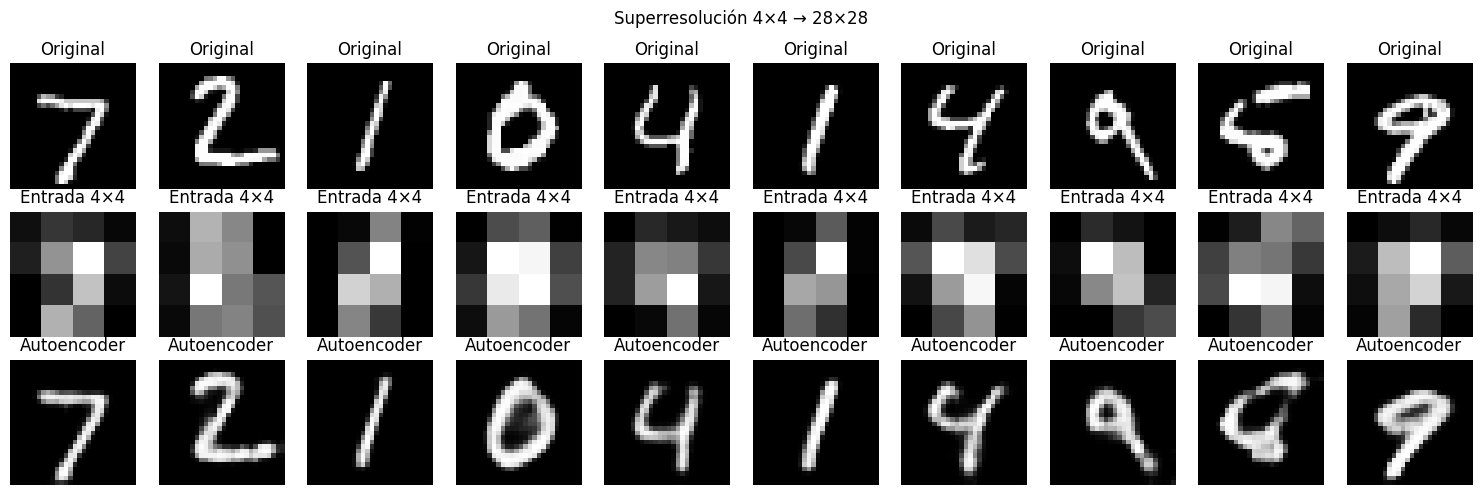


===== Convolucional 7×7 → 28×28 =====


7→28 | Epoch 1/10 | Loss (MSE): 0.0371


7→28 | Epoch 2/10 | Loss (MSE): 0.0127


7→28 | Epoch 3/10 | Loss (MSE): 0.0097


7→28 | Epoch 4/10 | Loss (MSE): 0.0082


7→28 | Epoch 5/10 | Loss (MSE): 0.0074


... (2 outputs left out)

7→28 | Epoch 8/10 | Loss (MSE): 0.0061


7→28 | Epoch 9/10 | Loss (MSE): 0.0059


7→28 | Epoch 10/10 | Loss (MSE): 0.0057


Test 7→28: MSE bilineal = 0.0452 | MSE autoencoder = 0.0055 | Parámetros: 211,905


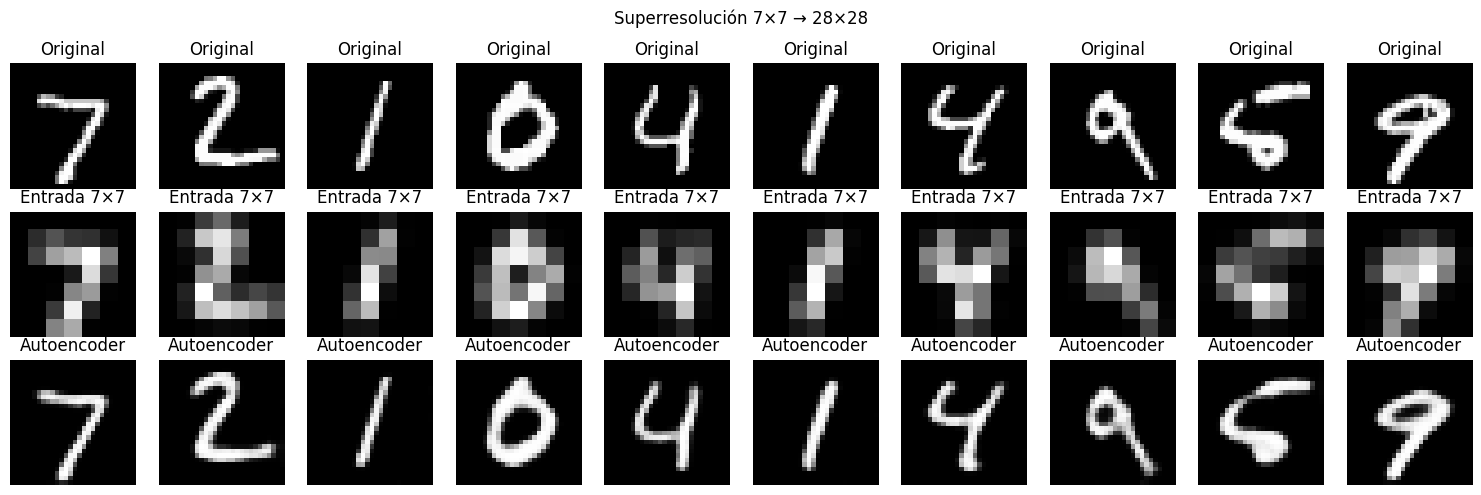


===== Convolucional 10×10 → 28×28 =====


10→28 | Epoch 1/10 | Loss (MSE): 0.0292


10→28 | Epoch 2/10 | Loss (MSE): 0.0076


10→28 | Epoch 3/10 | Loss (MSE): 0.0057


10→28 | Epoch 4/10 | Loss (MSE): 0.0048


10→28 | Epoch 5/10 | Loss (MSE): 0.0043


... (2 outputs left out)

10→28 | Epoch 8/10 | Loss (MSE): 0.0035


10→28 | Epoch 9/10 | Loss (MSE): 0.0034


10→28 | Epoch 10/10 | Loss (MSE): 0.0032


Test 10→28: MSE bilineal = 0.0306 | MSE autoencoder = 0.0031 | Parámetros: 316,353


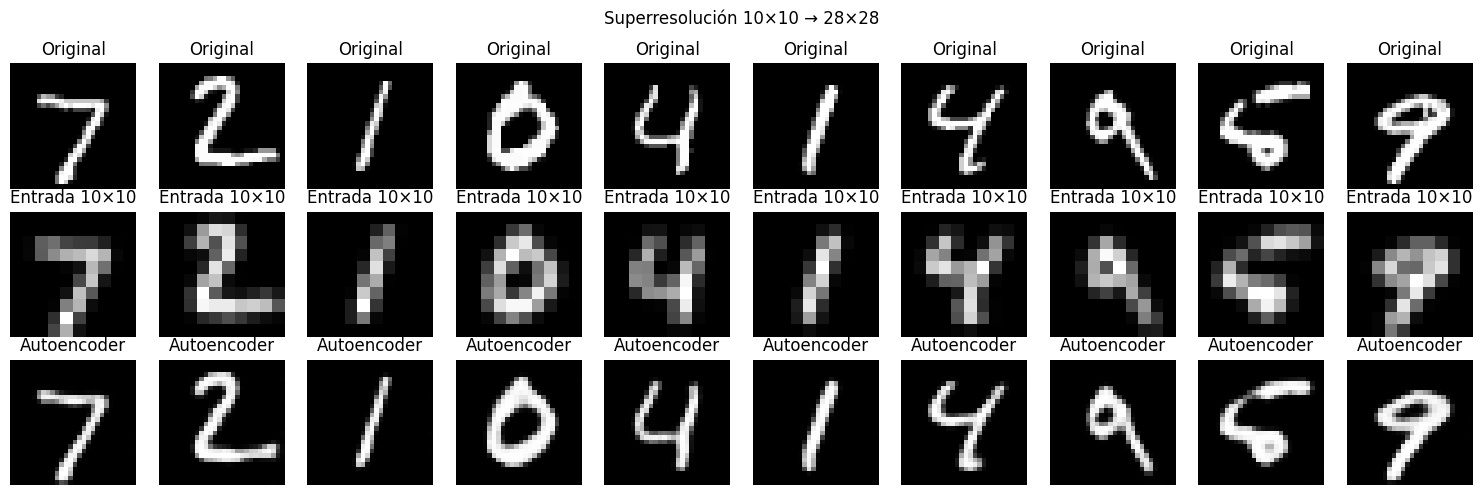


===== Convolucional 14×14 → 28×28 =====


14→28 | Epoch 1/10 | Loss (MSE): 0.0222


14→28 | Epoch 2/10 | Loss (MSE): 0.0057


14→28 | Epoch 3/10 | Loss (MSE): 0.0042


14→28 | Epoch 4/10 | Loss (MSE): 0.0035


14→28 | Epoch 5/10 | Loss (MSE): 0.0031


... (2 outputs left out)

14→28 | Epoch 8/10 | Loss (MSE): 0.0025


14→28 | Epoch 9/10 | Loss (MSE): 0.0024


14→28 | Epoch 10/10 | Loss (MSE): 0.0023


Test 14→28: MSE bilineal = 0.0198 | MSE autoencoder = 0.0023 | Parámetros: 512,961


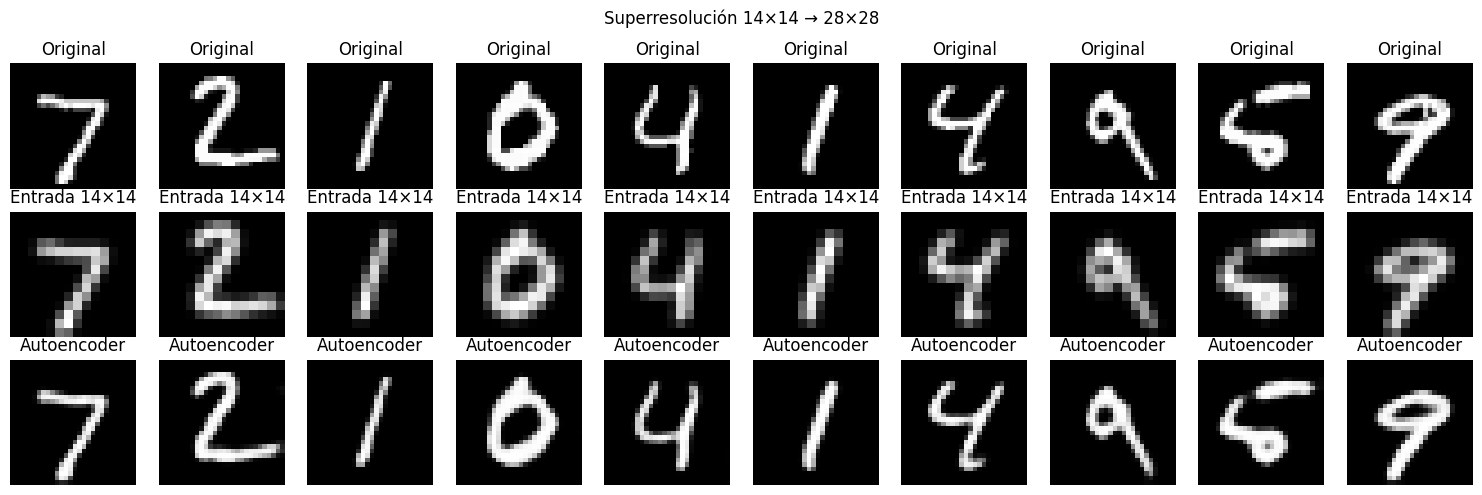


===== Convolucional 21×21 → 28×28 =====


21→28 | Epoch 1/10 | Loss (MSE): 0.0180


21→28 | Epoch 2/10 | Loss (MSE): 0.0044


21→28 | Epoch 3/10 | Loss (MSE): 0.0034


21→28 | Epoch 4/10 | Loss (MSE): 0.0029


21→28 | Epoch 5/10 | Loss (MSE): 0.0027


... (2 outputs left out)

21→28 | Epoch 8/10 | Loss (MSE): 0.0023


21→28 | Epoch 9/10 | Loss (MSE): 0.0022


21→28 | Epoch 10/10 | Loss (MSE): 0.0021


Test 21→28: MSE bilineal = 0.0083 | MSE autoencoder = 0.0021 | Parámetros: 1,014,721


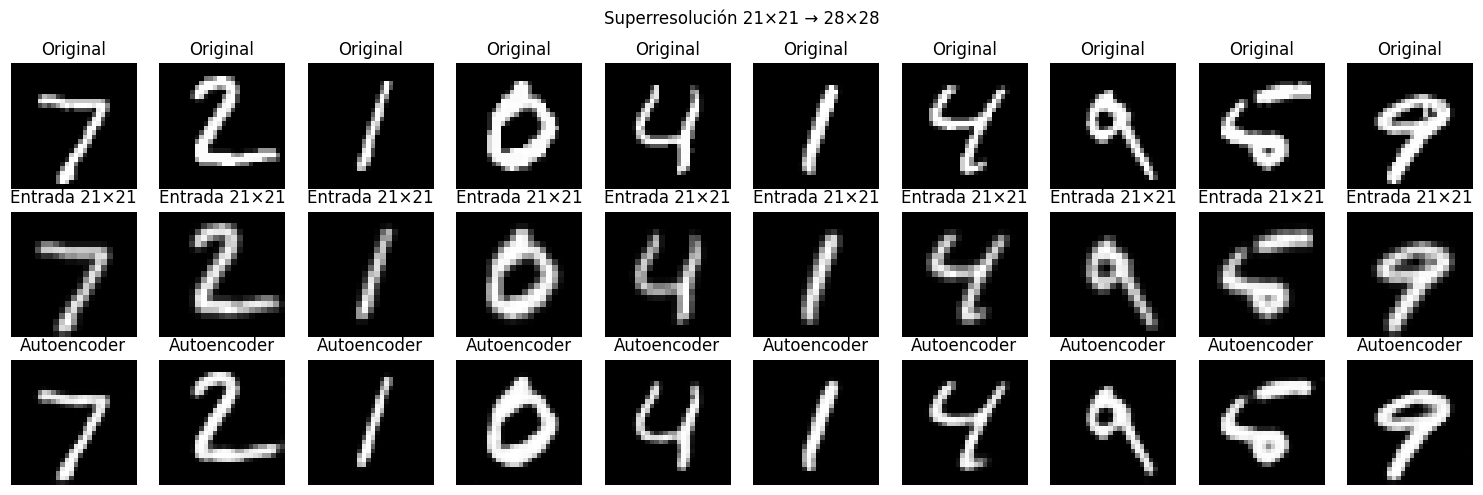

In [9]:
entradas = [4, 7, 10, 14, 21]
resultados_entrada = {}

for n in entradas:
    resultados_entrada[n] = experimento(n, 28)

 Entrada | MSE bilineal |  MSE autoencoder |  Mejora | Parámetros
------------------------------------------------------------------
     4×4 |       0.0664 |           0.0153 |    4.3x |    144,321
     7×7 |       0.0452 |           0.0055 |    8.2x |    211,905
   10×10 |       0.0306 |           0.0031 |    9.7x |    316,353
   14×14 |       0.0198 |           0.0023 |    8.8x |    512,961
   21×21 |       0.0083 |           0.0021 |    4.0x |  1,014,721


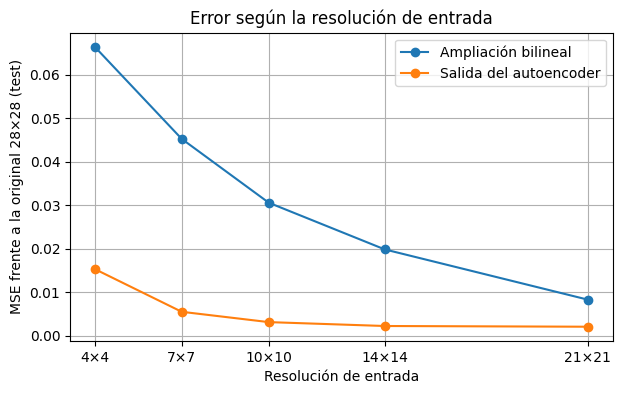

In [10]:
print(f"{'Entrada':>8} | {'MSE bilineal':>12} | {'MSE autoencoder':>16} | {'Mejora':>7} | {'Parámetros':>10}")
print("-" * 66)
for n, (mse_interp, mse_recon, num_params) in resultados_entrada.items():
    print(f"{f'{n}×{n}':>8} | {mse_interp:>12.4f} | {mse_recon:>16.4f} | {mse_interp / mse_recon:>6.1f}x | {num_params:>10,}")

plt.figure(figsize=(7, 4))
plt.plot(entradas, [resultados_entrada[n][0] for n in entradas], 'o-', label="Ampliación bilineal")
plt.plot(entradas, [resultados_entrada[n][1] for n in entradas], 'o-', label="Salida del autoencoder")
plt.xticks(entradas, [f"{n}×{n}" for n in entradas])
plt.xlabel("Resolución de entrada")
plt.ylabel("MSE frente a la original 28×28 (test)")
plt.title("Error según la resolución de entrada")
plt.legend()
plt.grid(True)
plt.show()

## Parte B · Otras resoluciones de salida

- **7×7 → 14×14:** el objetivo es la original reducida a 14×14.
- **14×14 → 56×56:** el objetivo es la original ampliada a 56×56. MNIST no tiene imágenes de 56×56 reales, así que el autoencoder aprende a generar una versión 56×56 suave de la original; el detalle extra que puede aportar está limitado por la propia imagen de 28×28.


===== Convolucional 7×7 → 14×14 =====


7→14 | Epoch 1/10 | Loss (MSE): 0.0138


7→14 | Epoch 2/10 | Loss (MSE): 0.0028


7→14 | Epoch 3/10 | Loss (MSE): 0.0020


7→14 | Epoch 4/10 | Loss (MSE): 0.0016


7→14 | Epoch 5/10 | Loss (MSE): 0.0014


... (2 outputs left out)

7→14 | Epoch 8/10 | Loss (MSE): 0.0011


7→14 | Epoch 9/10 | Loss (MSE): 0.0010


7→14 | Epoch 10/10 | Loss (MSE): 0.0010


Test 7→14: MSE bilineal = 0.0180 | MSE autoencoder = 0.0010 | Parámetros: 211,905


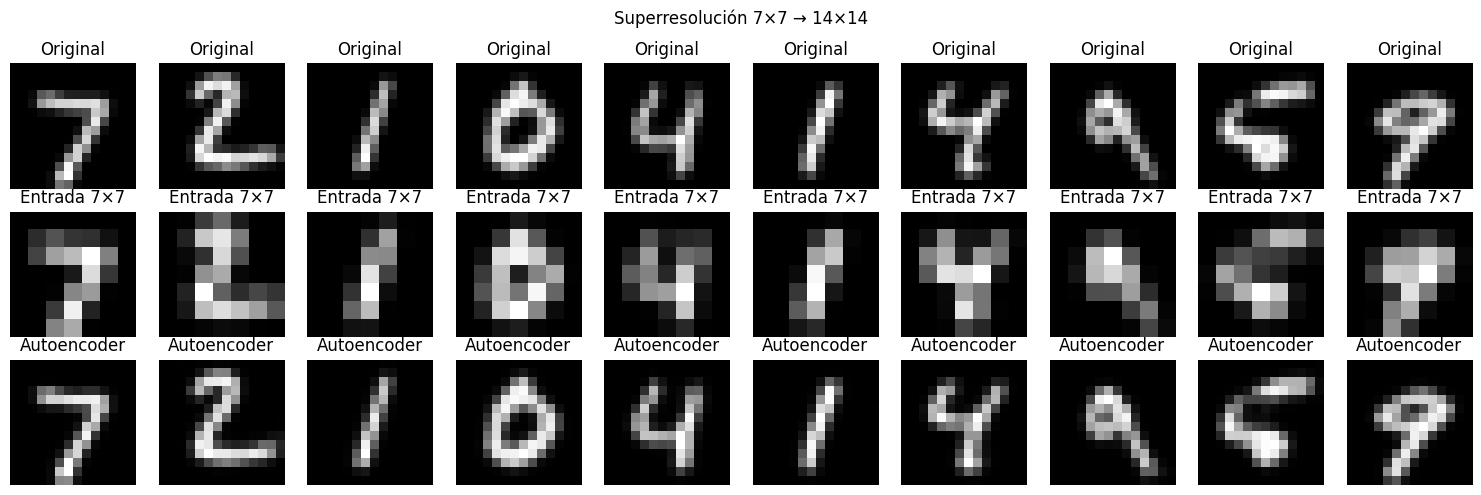


===== Convolucional 14×14 → 56×56 =====


14→56 | Epoch 1/10 | Loss (MSE): 0.0249


14→56 | Epoch 2/10 | Loss (MSE): 0.0041


14→56 | Epoch 3/10 | Loss (MSE): 0.0029


14→56 | Epoch 4/10 | Loss (MSE): 0.0023


14→56 | Epoch 5/10 | Loss (MSE): 0.0020


... (2 outputs left out)

14→56 | Epoch 8/10 | Loss (MSE): 0.0015


14→56 | Epoch 9/10 | Loss (MSE): 0.0014


14→56 | Epoch 10/10 | Loss (MSE): 0.0013


Test 14→56: MSE bilineal = 0.0108 | MSE autoencoder = 0.0013 | Parámetros: 514,049


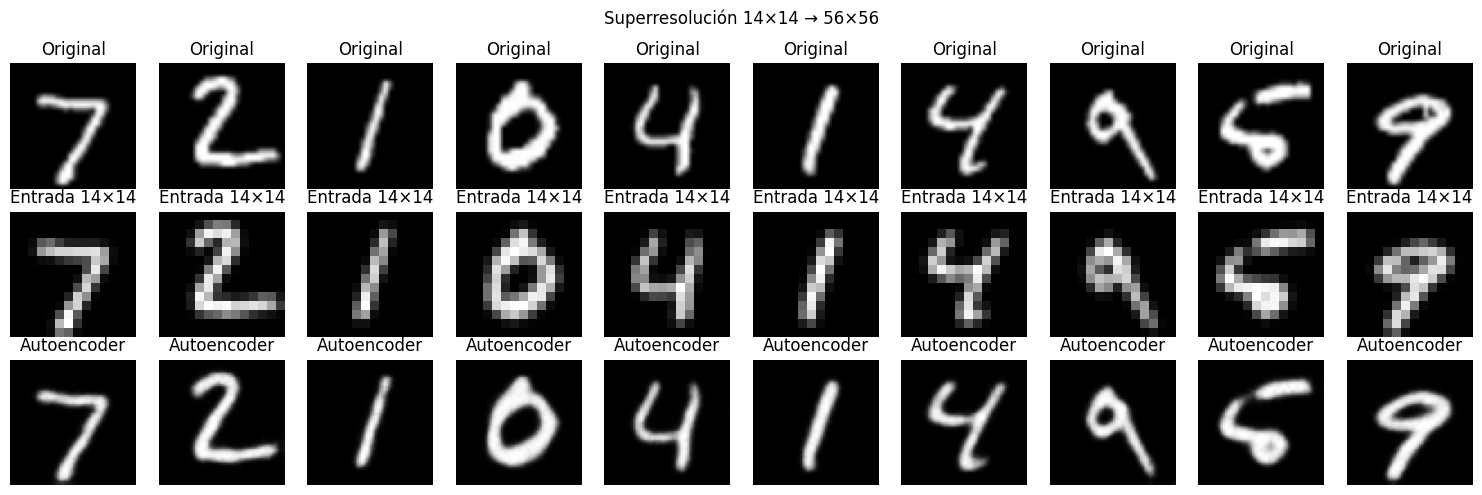

In [11]:
salidas = [(7, 14), (14, 56)]
resultados_salida = {}

for n_entrada, n_salida in salidas:
    resultados_salida[(n_entrada, n_salida)] = experimento(n_entrada, n_salida)

## Resumen: mismo factor de ampliación, distintos tamaños

Comparamos los cuatro casos de ampliación ×2 y ×4 (7→28 y 14→28 salen de la parte A).

In [12]:
casos = {
    (7, 14): resultados_salida[(7, 14)],
    (14, 28): resultados_entrada[14],
    (7, 28): resultados_entrada[7],
    (14, 56): resultados_salida[(14, 56)],
}

print(f"{'Caso':>9} | {'Factor':>6} | {'MSE bilineal':>12} | {'MSE autoencoder':>16} | {'Mejora':>7}")
print("-" * 62)
for (n_entrada, n_salida), (mse_interp, mse_recon, _) in casos.items():
    print(f"{f'{n_entrada}→{n_salida}':>9} | {f'×{n_salida // n_entrada}':>6} | {mse_interp:>12.4f} | {mse_recon:>16.4f} | {mse_interp / mse_recon:>6.1f}x")

     Caso | Factor | MSE bilineal |  MSE autoencoder |  Mejora
--------------------------------------------------------------
     7→14 |     ×2 |       0.0180 |           0.0010 |   18.9x
    14→28 |     ×2 |       0.0198 |           0.0023 |    8.8x
     7→28 |     ×4 |       0.0452 |           0.0055 |    8.2x
    14→56 |     ×4 |       0.0108 |           0.0013 |    8.1x


## Conclusiones

| Caso | Factor | MSE bilineal | MSE autoencoder | Mejora |
|---|---|---|---|---|
| 4→28 | ×7 | 0.0664 | 0.0153 | 4.3x |
| 7→28 | ×4 | 0.0452 | 0.0055 | 8.2x |
| 10→28 | ×2.8 | 0.0306 | 0.0031 | 9.7x |
| 14→28 | ×2 | 0.0198 | 0.0023 | 8.8x |
| 21→28 | ×1.33 | 0.0083 | 0.0021 | 4.0x |
| 7→14 | ×2 | 0.0180 | 0.0010 | 18.9x |
| 14→56 | ×4 | 0.0108 | 0.0013 | 8.1x |

- **Resolución de entrada (parte A):** el error del autoencoder baja al aumentar la entrada, de 0.0153 con 4×4 a 0.0021 con 21×21. El salto mayor está entre 4×4 y 7×7 (0.0153 → 0.0055). De 14×14 a 21×21 apenas mejora (0.0023 → 0.0021), aunque el modelo pasa de 513 000 a 1 015 000 parámetros. Con 4×4 la mayoría de los dígitos se reconocen, pero algunos salen deformados (el 5 de la figura).
- **Frente a la ampliación bilineal**, el autoencoder tiene menos error en todos los casos: entre 4.0 veces menos (21×21, donde la bilineal ya funciona bien: 0.0083) y 9.7 veces menos (10×10). Los resultados de 7→28 y 14→28 coinciden con los del `03` (0.0055 frente a 0.0054 y 0.0023).
- **Otras salidas (parte B), mismo factor:** con ×2, 7→14 da 0.0010 frente a 0.0023 de 14→28; con ×4, 14→56 da 0.0013 frente a 0.0055 de 7→28. Los objetivos de 14×14 y 56×56 son la original redimensionada, que es más suave que la original de 28×28, así que el MSE entre tamaños de salida distintos no se puede comparar directamente. Sí se ve que en los dos casos nuevos el autoencoder mejora mucho la bilineal (18.9 y 8.1 veces).
- **14→56:** MNIST no tiene imágenes reales de 56×56, así que el objetivo es la original ampliada. El autoencoder genera dígitos nítidos de 56×56, pero no puede añadir más detalle que el que tiene la imagen de 28×28 de partida.